
# Movie Recommendation System
### Recommender Systems Course Project

**Objective:** Build and evaluate a realistic movie recommender system using:
- Popularity-based recommendation
- Content-based filtering
- Collaborative filtering using SVD
- Hybrid recommendation
- Cold-start handling
- EDA and data analysis
- Precision@K, Recall@K, F1@K, RMSE, MAE, Diversity and Novelty
- Hybrid-weight experiments

**Dataset:** MovieLens Latest Small (automatically downloaded by the notebook)




## 1. Install Dependencies

In [ ]:

!pip -q install scikit-surprise joblib


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 30.5 MB/s eta 0:00:00


## 2. Import Libraries & Configuration

In [ ]:

import os
import zipfile
import urllib.request
import warnings
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.preprocessing import MinMaxScaler

from surprise import Dataset, Reader, SVD
from surprise import accuracy
from surprise.model_selection import train_test_split

import joblib

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
random.seed(RANDOM_STATE)

DATA_DIR = Path("data")
MODEL_DIR = Path("models")
DATA_DIR.mkdir(exist_ok=True)
MODEL_DIR.mkdir(exist_ok=True)

print("Environment ready.")


Environment ready.


## 3. Download & Load MovieLens Dataset

In [ ]:

URL = "https://files.grouplens.org/datasets/movielens/ml-latest-small.zip"
ZIP_PATH = DATA_DIR / "ml-latest-small.zip"
EXTRACT_DIR = DATA_DIR / "ml-latest-small"

if not EXTRACT_DIR.exists():
    print("Downloading MovieLens dataset...")
    urllib.request.urlretrieve(URL, ZIP_PATH)
    with zipfile.ZipFile(ZIP_PATH, "r") as z:
        z.extractall(DATA_DIR)
    print("Dataset downloaded and extracted.")
else:
    print("Dataset already exists.")

movies = pd.read_csv(EXTRACT_DIR / "movies.csv")
ratings = pd.read_csv(EXTRACT_DIR / "ratings.csv")

print(f"Movies:  {movies.shape[0]:,} rows")
print(f"Ratings: {ratings.shape[0]:,} rows")

display(movies.head())
display(ratings.head())


Dataset downloaded and extracted.
Movies:  9,742 rows
Ratings: 100,836 rows


,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy


,userId,movieId,rating,timestamp
0,1,1,4.0,964982703
1,1,3,4.0,964981247
2,1,6,4.0,964982224
3,1,47,5.0,964983815
4,1,50,5.0,964982931


## 4. Dataset Overview

In [ ]:

print("MOVIES")
print(movies.info())
print("\nRATINGS")
print(ratings.info())

print("\nUnique users:", ratings["userId"].nunique())
print("Unique movies in ratings:", ratings["movieId"].nunique())
print("Rating range:", ratings["rating"].min(), "to", ratings["rating"].max())
print("Missing values in movies:")
display(movies.isna().sum())
print("Missing values in ratings:")
display(ratings.isna().sum())

print("Duplicate movie rows:", movies.duplicated().sum())
print("Duplicate rating rows:", ratings.duplicated().sum())


MOVIES
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9742 entries, 0 to 9741
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   movieId  9742 non-null   int64 
 1   title    9742 non-null   object
 2   genres   9742 non-null   object
dtypes: int64(1), object(2)
memory usage: 228.5+ KB
None

RATINGS
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100836 entries, 0 to 100835
Data columns (total 4 columns):
 #   Column     Non-Null Count   Dtype  
---  ------     --------------   -----  
 0   userId     100836 non-null  int64  
 1   movieId    100836 non-null  int64  
 2   rating     100836 non-null  float64
 3   timestamp  100836 non-null  int64  
dtypes: float64(1), int64(3)
memory usage: 3.1 MB
None

Unique users: 610
Unique movies in ratings: 9724
Rating range: 0.5 to 5.0
Missing values in movies:


,0
movieId,0
title,0
genres,0


Missing values in ratings:


,0
userId,0
movieId,0
rating,0
timestamp,0


Duplicate movie rows: 0
Duplicate rating rows: 0


## 5. Data Cleaning & Feature Preparation

In [ ]:

movies = movies.drop_duplicates(subset="movieId").copy()
ratings = ratings.drop_duplicates(subset=["userId", "movieId"]).copy()

movies["genres"] = movies["genres"].fillna("").replace("(no genres listed)", "")
movies["title"] = movies["title"].fillna("")

movies["year"] = movies["title"].str.extract(r"\((\d{4})\)")[0]
movies["year"] = pd.to_numeric(movies["year"], errors="coerce")

movies["content"] = (
    movies["title"].str.replace(r"\(\d{4}\)", "", regex=True).str.strip()
    + " "
    + movies["genres"].str.replace("|", " ", regex=False)
).str.lower()

print("Cleaning complete.")
display(movies.head())


Cleaning complete.


,movieId,title,genres,year,content
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy,1995.0,toy story adventure animation children comedy ...
1,2,Jumanji (1995),Adventure|Children|Fantasy,1995.0,jumanji adventure children fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance,1995.0,grumpier old men comedy romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance,1995.0,waiting to exhale comedy drama romance
4,5,Father of the Bride Part II (1995),Comedy,1995.0,father of the bride part ii comedy


# 6. Exploratory Data Analysis (EDA)

### 6.1 Rating Distribution

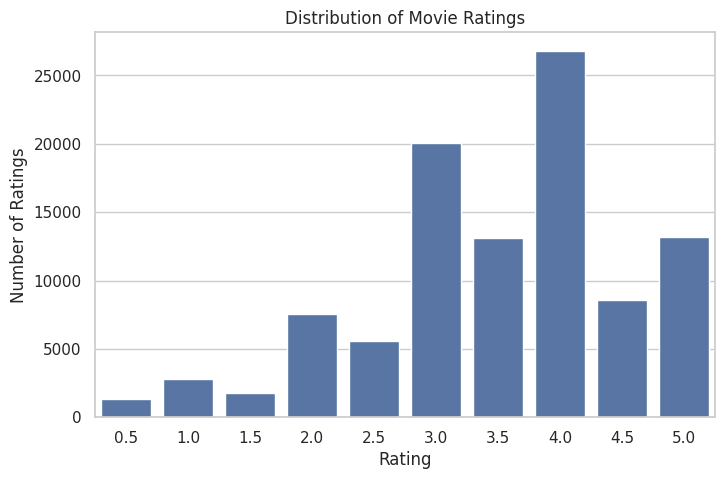

Mean rating: 3.502
Median rating: 3.5


In [ ]:

plt.figure(figsize=(8, 5))
sns.countplot(data=ratings, x="rating", order=sorted(ratings["rating"].unique()))
plt.title("Distribution of Movie Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of Ratings")
plt.show()

print("Mean rating:", round(ratings["rating"].mean(), 3))
print("Median rating:", ratings["rating"].median())


### 6.2 Ratings Per User

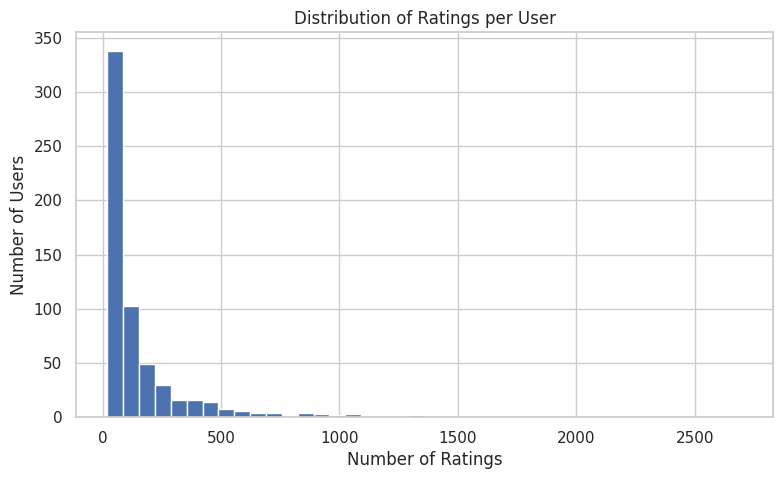

,ratings_per_user
count,610.000000
mean,165.304918
std,269.480584
min,20.000000
25%,35.000000
50%,70.500000
75%,168.000000
max,2698.000000


In [ ]:

ratings_per_user = ratings.groupby("userId").size()

plt.figure(figsize=(9, 5))
plt.hist(ratings_per_user, bins=40)
plt.title("Distribution of Ratings per User")
plt.xlabel("Number of Ratings")
plt.ylabel("Number of Users")
plt.show()

display(ratings_per_user.describe().to_frame("ratings_per_user"))


### 6.3 Ratings Per Movie

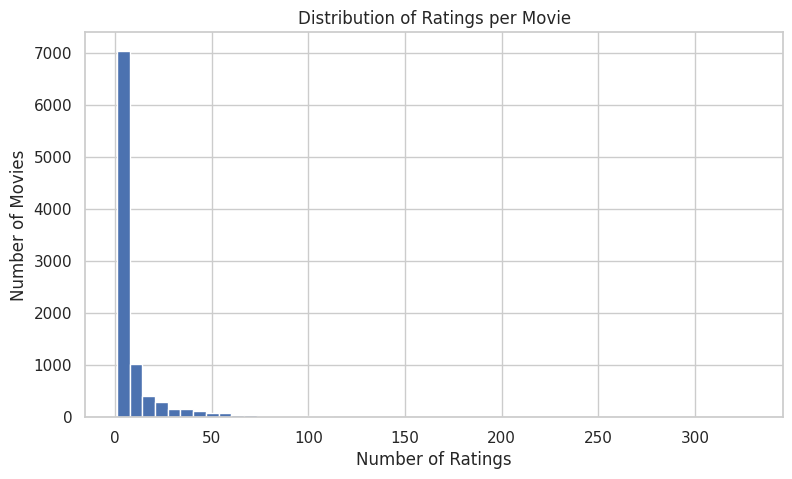

,ratings_per_movie
count,9724.000000
mean,10.369807
std,22.401005
min,1.000000
25%,1.000000
50%,3.000000
75%,9.000000
max,329.000000


In [ ]:

ratings_per_movie = ratings.groupby("movieId").size()

plt.figure(figsize=(9, 5))
plt.hist(ratings_per_movie, bins=50)
plt.title("Distribution of Ratings per Movie")
plt.xlabel("Number of Ratings")
plt.ylabel("Number of Movies")
plt.show()

display(ratings_per_movie.describe().to_frame("ratings_per_movie"))


### 6.4 Most Rated Movies

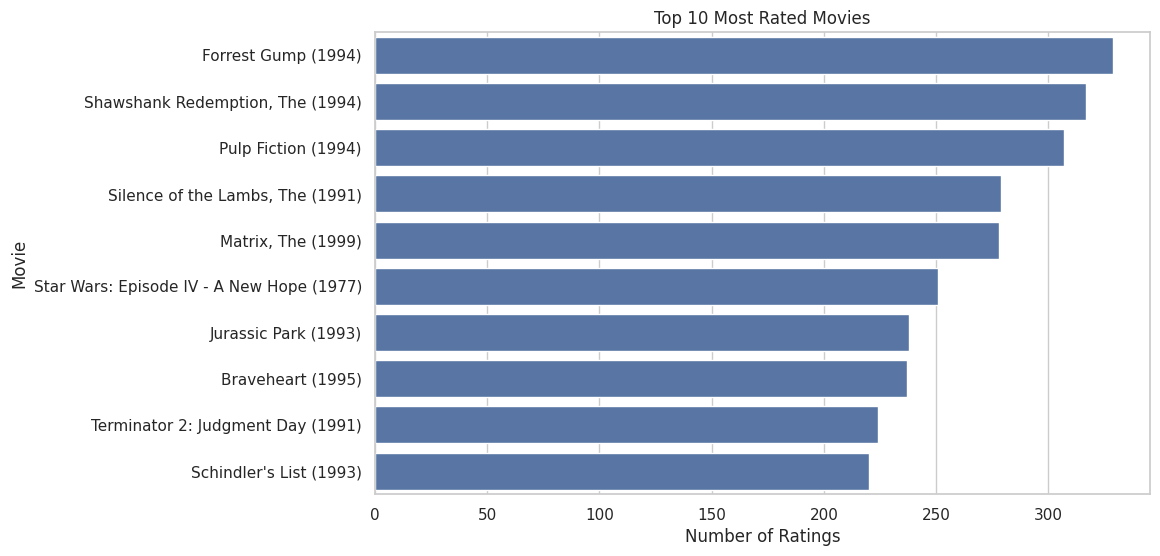

,title,rating_count,average_rating
314,Forrest Gump (1994),329,4.164134
277,"Shawshank Redemption, The (1994)",317,4.429022
257,Pulp Fiction (1994),307,4.197068
510,"Silence of the Lambs, The (1991)",279,4.161290
1938,"Matrix, The (1999)",278,4.192446
224,Star Wars: Episode IV - A New Hope (1977),251,4.231076
418,Jurassic Park (1993),238,3.750000
97,Braveheart (1995),237,4.031646
507,Terminator 2: Judgment Day (1991),224,3.970982
461,Schindler's List (1993),220,4.225000


In [ ]:

movie_stats = ratings.groupby("movieId").agg(
    rating_count=("rating", "count"),
    average_rating=("rating", "mean")
).reset_index().merge(movies[["movieId", "title"]], on="movieId")

top_most_rated = movie_stats.sort_values("rating_count", ascending=False).head(10)

plt.figure(figsize=(10, 6))
sns.barplot(data=top_most_rated, y="title", x="rating_count")
plt.title("Top 10 Most Rated Movies")
plt.xlabel("Number of Ratings")
plt.ylabel("Movie")
plt.show()

display(top_most_rated[["title", "rating_count", "average_rating"]])


### 6.5 Highest-Rated Movies (Minimum 50 Ratings)

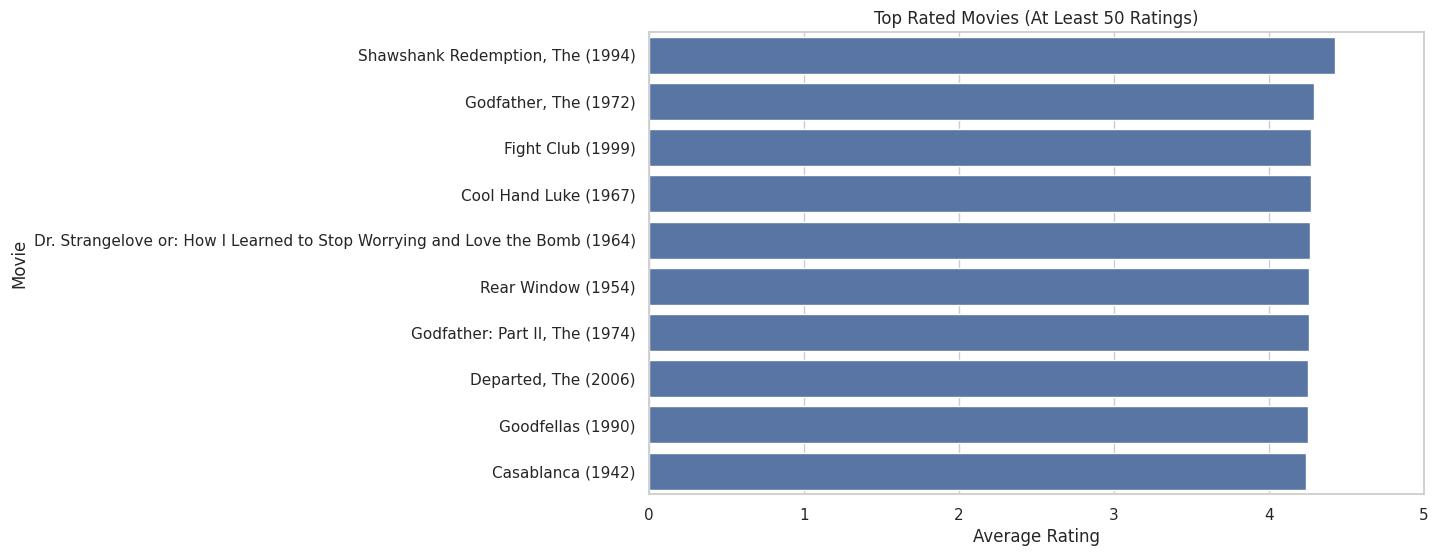

,title,average_rating,rating_count
277,"Shawshank Redemption, The (1994)",4.429022,317
659,"Godfather, The (1972)",4.289062,192
2224,Fight Club (1999),4.272936,218
974,Cool Hand Luke (1967),4.271930,57
602,Dr. Strangelove or: How I Learned to Stop Worr...,4.268041,97
686,Rear Window (1954),4.261905,84
921,"Godfather: Part II, The (1974)",4.259690,129
6298,"Departed, The (2006)",4.252336,107
913,Goodfellas (1990),4.250000,126
694,Casablanca (1942),4.240000,100


In [ ]:

MIN_RATINGS = 50

top_rated = movie_stats[movie_stats["rating_count"] >= MIN_RATINGS].sort_values(
    "average_rating", ascending=False
).head(10)

plt.figure(figsize=(10, 6))
sns.barplot(data=top_rated, y="title", x="average_rating")
plt.title(f"Top Rated Movies (At Least {MIN_RATINGS} Ratings)")
plt.xlabel("Average Rating")
plt.ylabel("Movie")
plt.xlim(0, 5)
plt.show()

display(top_rated[["title", "average_rating", "rating_count"]])


### 6.6 Genre Distribution

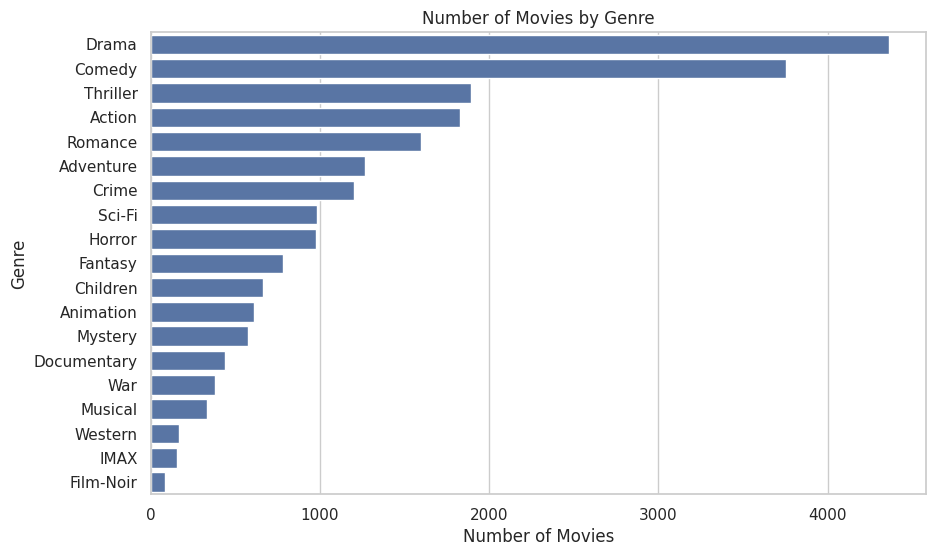

,movie_count
genre,
Drama,4361
Comedy,3756
Thriller,1894
Action,1828
Romance,1596
Adventure,1263
Crime,1199
Sci-Fi,980
Horror,978


In [ ]:

genre_counts = (
    movies.assign(genre=movies["genres"].str.split("|"))
          .explode("genre")
          .query("genre != ''")
          .groupby("genre")
          .size()
          .sort_values(ascending=False)
)

plt.figure(figsize=(10, 6))
sns.barplot(x=genre_counts.values, y=genre_counts.index)
plt.title("Number of Movies by Genre")
plt.xlabel("Number of Movies")
plt.ylabel("Genre")
plt.show()

display(genre_counts.to_frame("movie_count"))


### 6.7 Average Rating by Genre

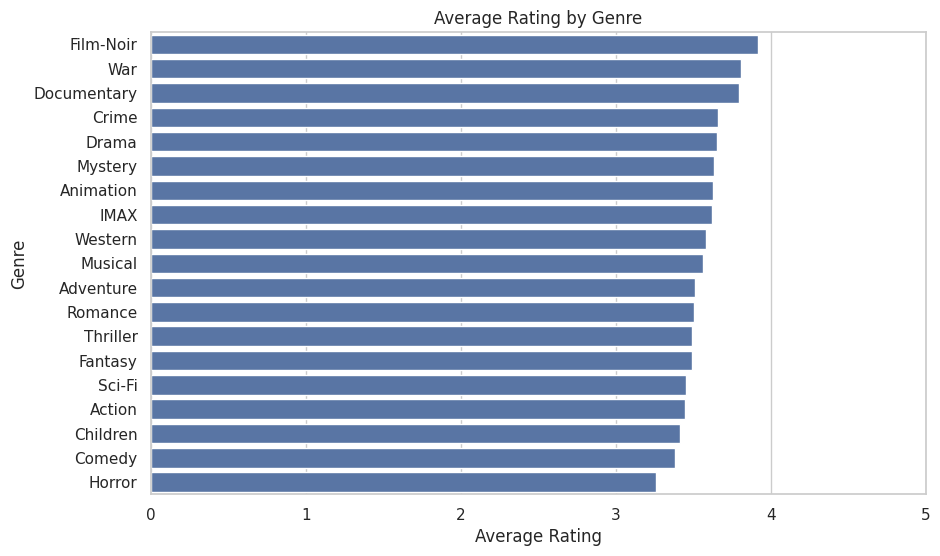

,avg_rating,rating_count
genre,,
Film-Noir,3.920115,870
War,3.808294,4859
Documentary,3.797785,1219
Crime,3.658294,16681
Drama,3.656184,41928
Mystery,3.632460,7674
Animation,3.629937,6988
IMAX,3.618335,4145
Western,3.583938,1930


In [ ]:

rating_genres = (
    ratings.merge(movies[["movieId", "genres"]], on="movieId")
           .assign(genre=lambda x: x["genres"].str.split("|"))
           .explode("genre")
           .query("genre != ''")
)

genre_rating_stats = (
    rating_genres.groupby("genre")
    .agg(avg_rating=("rating", "mean"), rating_count=("rating", "count"))
    .sort_values("avg_rating", ascending=False)
)

plt.figure(figsize=(10, 6))
sns.barplot(data=genre_rating_stats.reset_index(), x="avg_rating", y="genre")
plt.title("Average Rating by Genre")
plt.xlabel("Average Rating")
plt.ylabel("Genre")
plt.xlim(0, 5)
plt.show()

display(genre_rating_stats)


### 6.8 Ratings Over Time

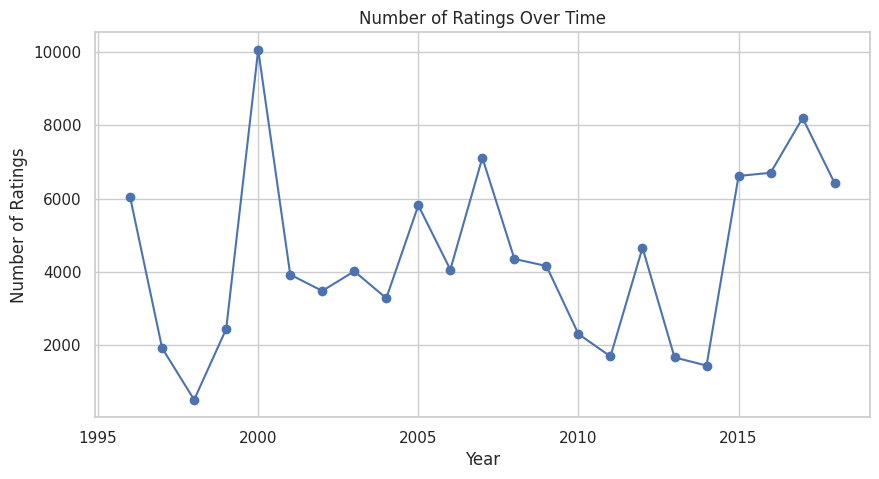

In [ ]:

ratings["date"] = pd.to_datetime(ratings["timestamp"], unit="s")
ratings_by_year = ratings.groupby(ratings["date"].dt.year).size()

plt.figure(figsize=(10, 5))
ratings_by_year.plot(marker="o")
plt.title("Number of Ratings Over Time")
plt.xlabel("Year")
plt.ylabel("Number of Ratings")
plt.show()


### 6.9 User–Item Matrix Sparsity

In [ ]:

n_users = ratings["userId"].nunique()
n_items = ratings["movieId"].nunique()
n_observed = len(ratings)

possible_interactions = n_users * n_items
sparsity = 1 - (n_observed / possible_interactions)

print(f"Unique users: {n_users:,}")
print(f"Unique movies: {n_items:,}")
print(f"Observed ratings: {n_observed:,}")
print(f"Possible user-movie interactions: {possible_interactions:,}")
print(f"Sparsity: {sparsity:.2%}")


Unique users: 610
Unique movies: 9,724
Observed ratings: 100,836
Possible user-movie interactions: 5,931,640
Sparsity: 98.30%


### 6.10 Long-Tail Movie Popularity

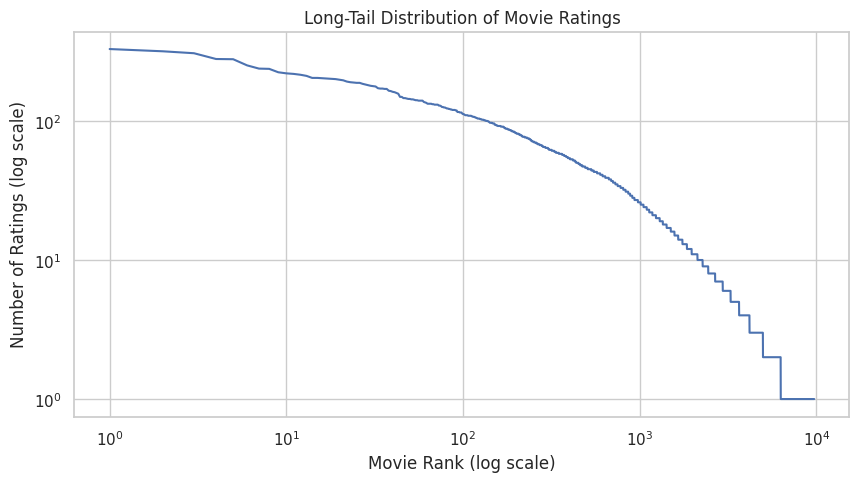

In [ ]:

sorted_counts = ratings_per_movie.sort_values(ascending=False).reset_index(drop=True)

plt.figure(figsize=(10, 5))
plt.plot(np.arange(1, len(sorted_counts) + 1), sorted_counts)
plt.yscale("log")
plt.xscale("log")
plt.title("Long-Tail Distribution of Movie Ratings")
plt.xlabel("Movie Rank (log scale)")
plt.ylabel("Number of Ratings (log scale)")
plt.show()


## 7. Popularity-Based Baseline

In [ ]:

C = ratings["rating"].mean()
m = movie_stats["rating_count"].quantile(0.90)

popular_movies = movie_stats.copy()
popular_movies["weighted_rating"] = (
    (popular_movies["rating_count"] / (popular_movies["rating_count"] + m))
    * popular_movies["average_rating"]
    + (m / (popular_movies["rating_count"] + m)) * C
)

popular_movies = popular_movies.sort_values("weighted_rating", ascending=False)

def recommend_popular(n=10):
    return popular_movies.head(n)[
        ["movieId", "title", "average_rating", "rating_count", "weighted_rating"]
    ].reset_index(drop=True)

display(recommend_popular(10))


,movieId,title,average_rating,rating_count,weighted_rating
0,318,"Shawshank Redemption, The (1994)",4.429022,317,4.356227
1,858,"Godfather, The (1972)",4.289062,192,4.191973
2,2959,Fight Club (1999),4.272936,218,4.187927
3,260,Star Wars: Episode IV - A New Hope (1977),4.231076,251,4.160223
4,50,"Usual Suspects, The (1995)",4.237745,204,4.151697
5,527,Schindler's List (1993),4.225000,220,4.145919
6,296,Pulp Fiction (1994),4.197068,307,4.140844
7,1196,Star Wars: Episode V - The Empire Strikes Back...,4.215640,211,4.134630
8,2571,"Matrix, The (1999)",4.192446,278,4.131285
9,1221,"Godfather: Part II, The (1974)",4.259690,129,4.128475


## 8. Content-Based Recommender

In [ ]:

tfidf = TfidfVectorizer(stop_words="english", ngram_range=(1, 2))
tfidf_matrix = tfidf.fit_transform(movies["content"])

content_similarity = cosine_similarity(tfidf_matrix, dense_output=False)

movie_to_index = pd.Series(movies.index, index=movies["title"]).drop_duplicates()

def recommend_content_based(movie_title, n=10):
    if movie_title not in movie_to_index:
        raise ValueError("Movie title not found. Use get_movie_matches() to search.")

    idx = movie_to_index[movie_title]
    scores = content_similarity[idx].toarray().ravel()
    candidate_indices = np.argsort(scores)[::-1]

    recommendations = []
    for i in candidate_indices:
        if i == idx:
            continue
        recommendations.append((i, scores[i]))
        if len(recommendations) >= n:
            break

    result = movies.iloc[[i for i, _ in recommendations]][
        ["movieId", "title", "genres"]
    ].copy()
    result["content_score"] = [score for _, score in recommendations]
    return result.reset_index(drop=True)

def get_movie_matches(query, n=10):
    mask = movies["title"].str.contains(query, case=False, na=False)
    return movies.loc[mask, ["movieId", "title", "genres"]].head(n)

display(get_movie_matches("Toy Story"))


,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
2355,3114,Toy Story 2 (1999),Adventure|Animation|Children|Comedy|Fantasy
7355,78499,Toy Story 3 (2010),Adventure|Animation|Children|Comedy|Fantasy|IMAX


### Test Content-Based Recommendations

In [ ]:

example_movie = "Toy Story (1995)"
display(recommend_content_based(example_movie, 10))


,movieId,title,genres,content_score
0,3114,Toy Story 2 (1999),Adventure|Animation|Children|Comedy|Fantasy,1.000000
1,78499,Toy Story 3 (2010),Adventure|Animation|Children|Comedy|Fantasy|IMAX,0.916714
2,3400,We're Back! A Dinosaur's Story (1993),Adventure|Animation|Children|Fantasy,0.493120
3,45074,"Wild, The (2006)",Adventure|Animation|Children|Comedy|Fantasy,0.427084
4,4886,"Monsters, Inc. (2001)",Adventure|Animation|Children|Comedy|Fantasy,0.415720
5,53121,Shrek the Third (2007),Adventure|Animation|Children|Comedy|Fantasy,0.411286
6,103755,Turbo (2013),Adventure|Animation|Children|Comedy|Fantasy,0.397720
7,166461,Moana (2016),Adventure|Animation|Children|Comedy|Fantasy,0.389648
8,2294,Antz (1998),Adventure|Animation|Children|Comedy|Fantasy,0.389648
9,130520,Home (2015),Adventure|Animation|Children|Comedy|Fantasy|Sc...,0.386680


## 9. Collaborative Filtering with SVD

In [ ]:

reader = Reader(rating_scale=(ratings["rating"].min(), ratings["rating"].max()))
surprise_data = Dataset.load_from_df(
    ratings[["userId", "movieId", "rating"]],
    reader
)

trainset, testset = train_test_split(
    surprise_data,
    test_size=0.20,
    random_state=RANDOM_STATE
)

svd = SVD(
    n_factors=100,
    n_epochs=20,
    lr_all=0.005,
    reg_all=0.02,
    random_state=RANDOM_STATE
)

svd.fit(trainset)

predictions = svd.test(testset)

rmse = accuracy.rmse(predictions, verbose=False)
mae = accuracy.mae(predictions, verbose=False)

print(f"Collaborative Filtering RMSE: {rmse:.4f}")
print(f"Collaborative Filtering MAE:  {mae:.4f}")


Collaborative Filtering RMSE: 0.8807
Collaborative Filtering MAE:  0.6766


### Collaborative Filtering Recommendation Function

In [ ]:

rated_by_user = ratings.groupby("userId")["movieId"].apply(set).to_dict()

def recommend_collaborative(user_id, n=10):
    if user_id not in rated_by_user:
        return recommend_popular(n)[["movieId", "title", "weighted_rating"]]

    rated_movies = rated_by_user[user_id]
    candidates = movies[~movies["movieId"].isin(rated_movies)].copy()

    candidates["predicted_rating"] = candidates["movieId"].apply(
        lambda mid: svd.predict(user_id, mid).est
    )

    return candidates.sort_values(
        "predicted_rating", ascending=False
    ).head(n)[["movieId", "title", "genres", "predicted_rating"]].reset_index(drop=True)

example_user = int(ratings["userId"].iloc[0])
print("Example user:", example_user)
display(recommend_collaborative(example_user, 10))


Example user: 1


,movieId,title,genres,predicted_rating
0,541,Blade Runner (1982),Action|Sci-Fi|Thriller,5.0
1,48516,"Departed, The (2006)",Crime|Drama|Thriller,5.0
2,750,Dr. Strangelove or: How I Learned to Stop Worr...,Comedy|War,5.0
3,1172,Cinema Paradiso (Nuovo cinema Paradiso) (1989),Drama,5.0
4,1945,On the Waterfront (1954),Crime|Drama,5.0
5,741,Ghost in the Shell (Kôkaku kidôtai) (1995),Animation|Sci-Fi,5.0
6,2019,Seven Samurai (Shichinin no samurai) (1954),Action|Adventure|Drama,5.0
7,912,Casablanca (1942),Drama|Romance,5.0
8,908,North by Northwest (1959),Action|Adventure|Mystery|Romance|Thriller,5.0
9,1104,"Streetcar Named Desire, A (1951)",Drama,5.0


## 10. Hybrid Recommender

In [ ]:
def recommend_hybrid(user_id, seed_movie, n=10, alpha=0.6):
    if seed_movie not in movie_to_index:
        raise ValueError("Seed movie not found.")

    seed_idx = movie_to_index[seed_movie]
    content_scores = content_similarity[seed_idx].toarray().ravel()

    candidates = movies.copy()
    candidates["content_score"] = content_scores


    rated_movies = rated_by_user.get(user_id, set())
    candidates = candidates[
        (candidates["movieId"] != movies.loc[seed_idx, "movieId"])
        & (~candidates["movieId"].isin(rated_movies))
    ].copy()

    candidates["cf_score"] = candidates["movieId"].apply(
        lambda mid: svd.predict(user_id, mid).est
    )

    content_min = candidates["content_score"].min()
    content_max = candidates["content_score"].max()

    if content_max > content_min:
        candidates["content_norm"] = (
            (candidates["content_score"] - content_min)
            / (content_max - content_min)
        )
    else:
        candidates["content_norm"] = 0.0

    rating_min = ratings["rating"].min()
    rating_max = ratings["rating"].max()

    candidates["cf_norm"] = (
        candidates["cf_score"] - rating_min
    ) / (rating_max - rating_min)

    candidates["hybrid_score"] = (
        alpha * candidates["content_norm"]
        + (1 - alpha) * candidates["cf_norm"]
    )

    result = candidates.sort_values(
        "hybrid_score", ascending=False
    ).head(n)

    return result[
        ["movieId", "title", "genres",
         "content_score", "cf_score", "hybrid_score"]
    ].reset_index(drop=True)

display(recommend_hybrid(example_user, example_movie, n=10, alpha=0.6))


,movieId,title,genres,content_score,cf_score,hybrid_score
0,3114,Toy Story 2 (1999),Adventure|Animation|Children|Comedy|Fantasy,1.000000,4.688720,0.972331
1,78499,Toy Story 3 (2010),Adventure|Animation|Children|Comedy|Fantasy|IMAX,0.916714,4.707699,0.924046
2,3400,We're Back! A Dinosaur's Story (1993),Adventure|Animation|Children|Fantasy,0.493120,4.390117,0.641660
3,4886,"Monsters, Inc. (2001)",Adventure|Animation|Children|Comedy|Fantasy,0.415720,4.603664,0.614202
4,4306,Shrek (2001),Adventure|Animation|Children|Comedy|Fantasy|Ro...,0.385384,4.740068,0.608125
5,68954,Up (2009),Adventure|Animation|Children|Drama,0.371372,4.830234,0.607733
6,45074,"Wild, The (2006)",Adventure|Animation|Children|Comedy|Fantasy,0.427084,4.198822,0.585035
7,103755,Turbo (2013),Adventure|Animation|Children|Comedy|Fantasy,0.397720,4.394291,0.584791
8,166461,Moana (2016),Adventure|Animation|Children|Comedy|Fantasy,0.389648,4.368475,0.577653
9,56152,Enchanted (2007),Adventure|Animation|Children|Comedy|Fantasy|Mu...,0.347534,4.524919,0.566291


## 11. Cold-Start Handling

In [ ]:

def recommend(user_id=None, seed_movie=None, n=10, alpha=0.6):

    if user_id is None or user_id not in rated_by_user:
        if seed_movie is not None and seed_movie in movie_to_index:
            return recommend_content_based(seed_movie, n)
        return recommend_popular(n)


    if seed_movie is not None and seed_movie in movie_to_index:
        return recommend_hybrid(user_id, seed_movie, n, alpha)


    return recommend_collaborative(user_id, n)

print("New-user fallback:")
display(recommend(user_id=None, seed_movie=None, n=5))

print("Existing-user + seed movie:")
display(recommend(user_id=example_user, seed_movie=example_movie, n=5))


New-user fallback:


,movieId,title,average_rating,rating_count,weighted_rating
0,318,"Shawshank Redemption, The (1994)",4.429022,317,4.356227
1,858,"Godfather, The (1972)",4.289062,192,4.191973
2,2959,Fight Club (1999),4.272936,218,4.187927
3,260,Star Wars: Episode IV - A New Hope (1977),4.231076,251,4.160223
4,50,"Usual Suspects, The (1995)",4.237745,204,4.151697


Existing-user + seed movie:


,movieId,title,genres,content_score,cf_score,hybrid_score
0,3114,Toy Story 2 (1999),Adventure|Animation|Children|Comedy|Fantasy,1.000000,4.688720,0.972331
1,78499,Toy Story 3 (2010),Adventure|Animation|Children|Comedy|Fantasy|IMAX,0.916714,4.707699,0.924046
2,3400,We're Back! A Dinosaur's Story (1993),Adventure|Animation|Children|Fantasy,0.493120,4.390117,0.641660
3,4886,"Monsters, Inc. (2001)",Adventure|Animation|Children|Comedy|Fantasy,0.415720,4.603664,0.614202
4,4306,Shrek (2001),Adventure|Animation|Children|Comedy|Fantasy|Ro...,0.385384,4.740068,0.608125


# 12. Evaluation


### Evaluation protocol

For Top-K evaluation, we treat a rating of **4.0 or higher** as a relevant interaction.

For each sampled test user:
1. Hide one or more relevant test ratings.
2. Generate recommendations from the training data.
3. Measure Precision@K, Recall@K and F1@K.




In [ ]:


eligible_users = (
    ratings.groupby("userId").size()
    .loc[lambda s: s >= 5]
    .index
)

eval_ratings = ratings[ratings["userId"].isin(eligible_users)].copy()

rng = np.random.default_rng(RANDOM_STATE)

test_rows = []
train_rows = []

for uid, group in eval_ratings.groupby("userId"):
    group = group.sample(frac=1, random_state=RANDOM_STATE)
    n_test = max(1, int(round(len(group) * 0.2)))
    test_rows.append(group.iloc[:n_test])
    train_rows.append(group.iloc[n_test:])

eval_train = pd.concat(train_rows).reset_index(drop=True)
eval_test = pd.concat(test_rows).reset_index(drop=True)

print("Evaluation train ratings:", len(eval_train))
print("Evaluation test ratings:", len(eval_test))
print("Evaluation users:", eval_test["userId"].nunique())


Evaluation train ratings: 80672
Evaluation test ratings: 20164
Evaluation users: 610


In [ ]:
eval_reader = Reader(rating_scale=(ratings["rating"].min(), ratings["rating"].max()))
eval_data = Dataset.load_from_df(
    eval_train[["userId", "movieId", "rating"]],
    eval_reader
)

eval_trainset = eval_data.build_full_trainset()

eval_svd = SVD(
    n_factors=100,
    n_epochs=20,
    lr_all=0.005,
    reg_all=0.02,
    random_state=RANDOM_STATE
)
eval_svd.fit(eval_trainset)

eval_test_predictions = eval_svd.test(
    list(eval_test[["userId", "movieId", "rating"]].itertuples(index=False, name=None))
)

eval_rmse = accuracy.rmse(eval_test_predictions, verbose=False)
eval_mae = accuracy.mae(eval_test_predictions, verbose=False)

print(f"Evaluation RMSE: {eval_rmse:.4f}")
print(f"Evaluation MAE:  {eval_mae:.4f}")


Evaluation RMSE: 0.8774
Evaluation MAE:  0.6743


### Precision@K / Recall@K / F1@K

In [ ]:
train_user_items = eval_train.groupby("userId")["movieId"].apply(set).to_dict()

all_movie_ids = set(movies["movieId"])

movie_id_to_title = movies.set_index("movieId")["title"].to_dict()

def top_k_collaborative_eval(user_id, k=10):
    seen = train_user_items.get(user_id, set())
    candidates = list(all_movie_ids - seen)

    scored = []
    for mid in candidates:
        scored.append((mid, eval_svd.predict(user_id, mid).est))

    scored.sort(key=lambda x: x[1], reverse=True)
    return [mid for mid, _ in scored[:k]]

test_relevant = (
    eval_test[eval_test["rating"] >= 4.0]
    .groupby("userId")["movieId"]
    .apply(set)
    .to_dict()
)

def precision_recall_f1_at_k(k=10, max_users=100):
    users = list(test_relevant.keys())[:max_users]
    precisions, recalls, f1s = [], [], []

    for uid in users:
        relevant = test_relevant[uid]
        if not relevant:
            continue

        recommended = set(top_k_collaborative_eval(uid, k))
        hits = len(recommended & relevant)

        precision = hits / k
        recall = hits / len(relevant)
        f1 = (
            2 * precision * recall / (precision + recall)
            if precision + recall > 0 else 0
        )

        precisions.append(precision)
        recalls.append(recall)
        f1s.append(f1)

    return {
        "Precision@K": np.mean(precisions) if precisions else 0,
        "Recall@K": np.mean(recalls) if recalls else 0,
        "F1@K": np.mean(f1s) if f1s else 0
    }

metrics_at_5 = precision_recall_f1_at_k(5, max_users=100)
metrics_at_10 = precision_recall_f1_at_k(10, max_users=100)

print("Top-K Evaluation")
print("K=5 :", {k: round(v, 4) for k, v in metrics_at_5.items()})
print("K=10:", {k: round(v, 4) for k, v in metrics_at_10.items()})


Top-K Evaluation
K=5 : {'Precision@K': np.float64(0.048), 'Recall@K': np.float64(0.0149), 'F1@K': np.float64(0.0205)}
K=10: {'Precision@K': np.float64(0.05), 'Recall@K': np.float64(0.0392), 'F1@K': np.float64(0.0359)}


## 13. Hybrid Evaluation Sanity Check

The held-out RMSE/MAE evaluation applies to the SVD rating-prediction model. The hybrid model is a ranking system, so we evaluate its recommendation lists using diversity, novelty, and explicit recommendation inspection rather than inventing an RMSE score.

In [ ]:
import numpy as np
import pandas as pd
from itertools import combinations

def recommendation_diversity(movie_ids):
    """Measures how different the recommended movies are from each other."""
    indices = [
        movie_to_index[mid]
        for mid in movie_ids
        if mid in movie_to_index
    ]

    if len(indices) < 2:
        return 0.0

    similarities = []

    for i, j in combinations(indices, 2):
        similarity = float(
            cosine_similarity(
                tfidf_matrix[i],
                tfidf_matrix[j]
            )[0, 0]
        )
        similarities.append(similarity)

    return float(1 - np.mean(similarities))


def recommendation_novelty(movie_ids):
    """Measures how uncommon the recommended movies are in the dataset."""
    movie_counts = ratings["movieId"].value_counts()
    total_ratings = len(ratings)

    scores = []

    for movie_id in movie_ids:
        count = movie_counts.get(movie_id, 0)

        if count > 0 and total_ratings > 0:
            probability = count / total_ratings
            scores.append(-np.log2(probability))

    return float(np.mean(scores)) if scores else 0.0

In [ ]:
hybrid_rows = []

for alpha in [0.4, 0.6, 0.8]:
    recs = recommend_hybrid(
        example_user,
        example_movie,
        n=10,
        alpha=alpha
    )

    mids = recs["movieId"].tolist()

    hybrid_rows.append({
        "alpha": alpha,
        "diversity": recommendation_diversity(mids),
        "novelty": recommendation_novelty(mids)
    })

hybrid_summary = pd.DataFrame(hybrid_rows)

display(hybrid_summary)

,alpha,diversity,novelty
0,0.4,0.0,12.045046
1,0.6,0.0,12.525782
2,0.8,0.0,12.385343


## 14. Diversity & Novelty

In [ ]:

def recommendation_diversity(movie_ids):
    subset = movies[movies["movieId"].isin(movie_ids)].copy()
    if len(subset) < 2:
        return 0.0

    vectors = tfidf_matrix[subset.index]
    sim = cosine_similarity(vectors)

    # Average pairwise dissimilarity
    n = sim.shape[0]
    values = []
    for i in range(n):
        for j in range(i + 1, n):
            values.append(1 - sim[i, j])

    return float(np.mean(values)) if values else 0.0

movie_frequency = ratings["movieId"].value_counts()
total_ratings = len(ratings)

def recommendation_novelty(movie_ids):
    # Popular items have lower novelty; rarer items have higher novelty.
    values = []
    for mid in movie_ids:
        count = movie_frequency.get(mid, 0)
        probability = max(count / total_ratings, 1 / total_ratings)
        values.append(-np.log2(probability))
    return float(np.mean(values)) if values else 0.0

sample_recs = recommend_hybrid(
    example_user,
    example_movie,
    n=10,
    alpha=0.6
)

sample_ids = sample_recs["movieId"].tolist()

print("Sample Hybrid Recommendation Diversity:",
      round(recommendation_diversity(sample_ids), 4))

print("Sample Hybrid Recommendation Novelty:",
      round(recommendation_novelty(sample_ids), 4))


Sample Hybrid Recommendation Diversity: 0.5974
Sample Hybrid Recommendation Novelty: 12.5258


## 15. Hybrid Weight Experiment

,alpha,mean_diversity,mean_novelty
0,0.0,0.981862,10.703421
1,0.2,0.932715,11.097505
2,0.4,0.709908,12.811123
3,0.6,0.676890,13.172798
4,0.8,0.655688,13.429772
5,1.0,0.636362,13.679622


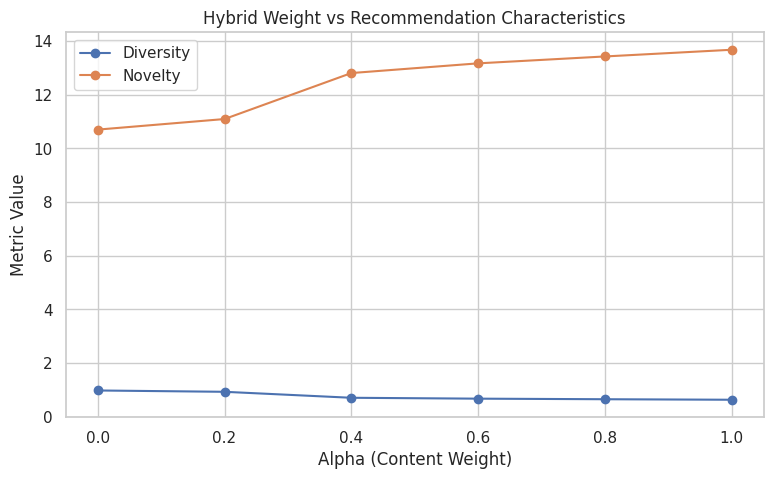

In [ ]:

candidate_users = ratings["userId"].drop_duplicates().sample(
    min(20, ratings["userId"].nunique()),
    random_state=RANDOM_STATE
).tolist()

candidate_seed_movies = (
    ratings["movieId"].value_counts()
    .head(50)
    .index
    .tolist()
)

alpha_values = [0.0, 0.2, 0.4, 0.6, 0.8, 1.0]

experiment_rows = []

for alpha in alpha_values:
    diversities = []
    novelties = []

    for uid in candidate_users[:10]:
      user_rated = list(rated_by_user.get(uid, set()))
        if not user_rated:
            continue

        seed_mid = user_rated[0]
        seed_title = movies.loc[movies["movieId"] == seed_mid, "title"].iloc[0]

        try:
            recs = recommend_hybrid(uid, seed_title, n=10, alpha=alpha)
            mids = recs["movieId"].tolist()

            diversities.append(recommendation_diversity(mids))
            novelties.append(recommendation_novelty(mids))
        except Exception:
            continue

    experiment_rows.append({
        "alpha": alpha,
        "mean_diversity": np.mean(diversities) if diversities else 0,
        "mean_novelty": np.mean(novelties) if novelties else 0
    })

alpha_results = pd.DataFrame(experiment_rows)
display(alpha_results)

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(alpha_results["alpha"], alpha_results["mean_diversity"], marker="o", label="Diversity")
ax.plot(alpha_results["alpha"], alpha_results["mean_novelty"], marker="o", label="Novelty")
ax.set_title("Hybrid Weight vs Recommendation Characteristics")
ax.set_xlabel("Alpha (Content Weight)")
ax.set_ylabel("Metric Value")
ax.legend()
plt.show()


## 16. Model Comparison Summary

In [ ]:

comparison = pd.DataFrame({
    "Model": [
        "Popularity-Based",
        "Content-Based",
        "Collaborative (SVD)",
        "Hybrid"
    ],
    "Approach": [
        "Weighted popularity baseline",
        "TF-IDF + cosine similarity",
        "SVD matrix factorization",
        "Content + collaborative weighted score"
    ],
    "RMSE": [
        np.nan,
        np.nan,
        eval_rmse,
        np.nan
    ],
    "MAE": [
        np.nan,
        np.nan,
        eval_mae,
        np.nan
    ]
})

display(comparison)


,Model,Approach,RMSE,MAE
0,Popularity-Based,Weighted popularity baseline,NaN,NaN
1,Content-Based,TF-IDF + cosine similarity,NaN,NaN
2,Collaborative (SVD),SVD matrix factorization,0.877436,0.674265
3,Hybrid,Content + collaborative weighted score,NaN,NaN


## 17. Generate a Final Demonstration Recommendation

In [ ]:

demo_user = example_user

user_history = (
    ratings[ratings["userId"] == demo_user]
    .merge(movies[["movieId", "title"]], on="movieId")
    .sort_values("rating", ascending=False)
)

print(f"Demo User: {demo_user}")
display(user_history[["title", "rating"]].head(10))

demo_seed = user_history.iloc[0]["title"]
print(f"\nSeed Movie: {demo_seed}")

final_demo = recommend_hybrid(
    demo_user,
    demo_seed,
    n=10,
    alpha=0.6
)

display(final_demo)


Demo User: 1


,title,rating
3,Seven (a.k.a. Se7en) (1995),5.0
4,"Usual Suspects, The (1995)",5.0
6,Bottle Rocket (1996),5.0
13,Dumb & Dumber (Dumb and Dumber) (1994),5.0
11,Billy Madison (1995),5.0
10,Desperado (1995),5.0
9,Canadian Bacon (1995),5.0
8,Rob Roy (1995),5.0
35,Pinocchio (1940),5.0
31,Tombstone (1993),5.0



Seed Movie: Seven (a.k.a. Se7en) (1995)


,movieId,title,genres,content_score,cf_score,hybrid_score
0,5475,Z (1969),Drama|Mystery|Thriller,0.266885,4.004531,0.911514
1,102903,Now You See Me (2013),Crime|Mystery|Thriller,0.233705,4.318327,0.864812
2,50740,Seven Up! (1964),Documentary,0.217447,4.448442,0.839828
3,4720,"Others, The (2001)",Drama|Horror|Mystery|Thriller,0.209249,4.381691,0.815465
4,107997,We Are What We Are (2013),Drama|Horror|Mystery|Thriller,0.209249,4.053879,0.786326
5,31921,"Seven-Per-Cent Solution, The (1976)",Adventure|Comedy|Crime|Drama|Mystery|Thriller,0.195491,4.335450,0.780424
6,3634,Seven Days in May (1964),Thriller,0.185777,4.348505,0.759745
7,6785,Seven Brides for Seven Brothers (1954),Comedy|Musical|Romance|Western,0.185787,4.242179,0.750316
8,26693,It (1990),Drama|Fantasy|Horror|Mystery|Thriller,0.178749,4.162479,0.727409
9,4226,Memento (2000),Mystery|Thriller,0.148042,4.880058,0.722160


## 17. What the Project Actually Produces

In [ ]:
print("CONTENT MODEL")
print("TF-IDF matrix:", tfidf_matrix.shape)
print("SVD factors:", svd.n_factors)
print("Default hybrid alpha:", 0.6)

print("\nExample hybrid recommendations:")
display(
    recommend_hybrid(
        example_user,
        example_movie,
        n=5,
        alpha=0.6
    )
)

CONTENT MODEL
TF-IDF matrix: (9742, 27821)
SVD factors: 100
Default hybrid alpha: 0.6

Example hybrid recommendations:


,movieId,title,genres,content_score,cf_score,hybrid_score
0,3114,Toy Story 2 (1999),Adventure|Animation|Children|Comedy|Fantasy,1.000000,4.688720,0.972331
1,78499,Toy Story 3 (2010),Adventure|Animation|Children|Comedy|Fantasy|IMAX,0.916714,4.707699,0.924046
2,3400,We're Back! A Dinosaur's Story (1993),Adventure|Animation|Children|Fantasy,0.493120,4.390117,0.641660
3,4886,"Monsters, Inc. (2001)",Adventure|Animation|Children|Comedy|Fantasy,0.415720,4.603664,0.614202
4,4306,Shrek (2001),Adventure|Animation|Children|Comedy|Fantasy|Ro...,0.385384,4.740068,0.608125


## 18. Export Models for the Streamlit App

In [ ]:
import joblib
from pathlib import Path
from google.colab import files

artifacts = {
    "movies": movies.copy().reset_index(drop=True),
    "ratings": ratings.copy(),
    "tfidf_matrix": tfidf_matrix,
    "svd": svd,
    "popular_movies": popular_movies.copy(),
    "rated_by_user": rated_by_user,
    "rating_min": float(ratings["rating"].min()),
    "rating_max": float(ratings["rating"].max()),
}

out = Path("recommender_artifacts.pkl")
joblib.dump(artifacts, out, compress=3)

print("Artifact saved:", out)
print("Size:", round(out.stat().st_size / (1024**2), 1), "MB")

files.download(str(out))

Artifact saved: recommender_artifacts.pkl
Size: 9.9 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>